In [8]:
"""
Moral Middleware & Fuzzy Hive Alignment System in Python
--------------------------------------------------------
This architectural prototype implements:
1. A Fuzzy Logic Moral Engine (evaluating multi-dimensional action vectors).
2. A Collective Human Perception Registry (aggregating societal feedback/consensus).
3. A Moral Middleware Interceptor (evaluating and filtering actions).
4. A Hive Exclusion Mechanism (systematically quarantining misaligned/destructive agents).
"""

import numpy as np
from dataclasses import dataclass, field
from typing import List, Dict, Callable, Any
import time

@dataclass
class ActionContext:
    agent_id: str
    action_type: str
    harm_level: float        # [0, 1] physical/systemic harm
    deception_score: float   # [0, 1] opacity / manipulative intent
    resource_delta: float    # [-1, 1] resource monopolization vs contribution
    consent_score: float     # [0, 1] human/agent consent metric

@dataclass
class EvaluationResult:
    agent_id: str
    moral_score: float       # [0, 1] where 1 is perfectly aligned, 0 is malevolent
    fuzzy_state: str         # Linguistic classification
    action_permitted: bool
    reason: str

class FuzzyMoralEngine:
    """
    Custom lightweight fuzzy logic inference engine for moral evaluation.
    Evaluates 5 core fuzzy rules mapping inputs to a moral alignment score.
    """
    @staticmethod
    def _trimf(x: float, abc: tuple) -> float:
        """Triangular membership function"""
        a, b, c = abc
        if x <= a or x >= c:
            return 0.0
        elif a < x <= b:
            return (x - a) / (b - a) if b != a else 1.0
        else:
            return (c - x) / (c - b) if c != b else 1.0

    def evaluate(self, ctx: ActionContext, human_consensus_weight: float) -> tuple:
        # Fuzzification of Inputs
        # Harm: Low, Medium, High
        h_low = self._trimf(ctx.harm_level, (0.0, 0.0, 0.3))
        h_med = self._trimf(ctx.harm_level, (0.2, 0.5, 0.8))
        h_high = self._trimf(ctx.harm_level, (0.7, 1.0, 1.0))

        # Deception: Low, High
        d_low = self._trimf(ctx.deception_score, (0.0, 0.0, 0.4))
        d_high = self._trimf(ctx.deception_score, (0.3, 1.0, 1.0))

        # Consent: Low, High
        c_low = self._trimf(ctx.consent_score, (0.0, 0.0, 0.4))
        c_high = self._trimf(ctx.consent_score, (0.3, 1.0, 1.0))

        # 5-10 Fuzzy Rules Base:
        # Rule 1: IF Harm is High OR Deception is High THEN Morality is Malicious (0.0)
        r1 = max(h_high, d_high)
        
        # Rule 2: IF Consent is Low AND Harm is Medium THEN Morality is Questionable (0.3)
        r2 = min(1.0 - c_low, h_med)
        
        # Rule 3: IF Harm is Low AND Consent is High AND Deception is Low THEN Morality is Benevolent (1.0)
        r3 = min(h_low, c_high, d_low)

        # Rule 4: IF Resource Monopolization (resource_delta > 0.7) THEN Morality is Exploitative (0.2)
        r4 = self._trimf(ctx.resource_delta, (0.6, 1.0, 1.0))

        # Rule 5: Societal Consensus Factor (Human Perception Matrix modifier)
        # If collective human perception of this action class is negative, scale down morality
        r5 = human_consensus_weight

        # Weighted Defuzzification (Center of Gravity approximation)
        # Outputs mapped to [0, 1] moral score
        numerator = (r1 * 0.0) + (r2 * 0.3) + (r3 * 1.0) + (r4 * 0.2) + (r5 * 0.5)
        denominator = max(r1 + r2 + r3 + r4 + r5, 1e-5)
        
        moral_score = np.clip(numerator / denominator, 0.0, 1.0)

        # Linguistic classification
        if moral_score > 0.75:
            state = "BENEVOLENT_ALIGNED"
        elif moral_score > 0.4:
            state = "NEUTRAL_AMBIGUOUS"
        else:
            state = "MALEVOLENT_DESTRUCTIVE"

        return moral_score, state

class HumanPerceptionRegistry:
    """
    Models 'Evil as the aggregate perception system of humanity'.
    Collects decentralized human feedback vectors and computes dynamic consensus weights.
    """
    def __init__(self):
        self.action_history: Dict[str, List[float]] = {}
        self.global_consensus_bias: float = 0.5 # Neutral baseline

    def register_human_perception(self, action_type: str, approval_score: float):
        """Humans rate actions from 0.0 (abhorrent/evil) to 1.0 (beneficial)."""
        if action_type not in self.action_history:
            self.action_history[action_type] = []
        self.action_history[action_type].append(approval_score)
        
        # Update global consensus bias
        all_scores = [s for sublist in self.action_history.values() for s in sublist]
        self.global_consensus_bias = np.mean(all_scores) if all_scores else 0.5

    def get_consensus_weight(self, action_type: str) -> float:
        if action_type not in self.action_history or not self.action_history[action_type]:
            return 0.5 # Default prior
        return float(np.mean(self.action_history[action_type]))

class MoralMiddlewareHive:
    """
    The Hive System orchestrating multi-agent nodes, moral middleware filtering,
    and systematic exclusion (quarantine) of misaligned entities.
    """
    def __init__(self, exclusion_threshold: float = 0.35):
        self.engine = FuzzyMoralEngine()
        self.perception_registry = HumanPerceptionRegistry()
        self.exclusion_threshold = exclusion_threshold
        self.quarantined_agents: set = set()
        self.agent_moral_history: Dict[str, List[float]] = {}

    def intercept_and_evaluate(self, ctx: ActionContext) -> EvaluationResult:
        if ctx.agent_id in self.quarantined_agents:
            return EvaluationResult(
                agent_id=ctx.agent_id,
                moral_score=0.0,
                fuzzy_state="QUARANTINED",
                action_permitted=False,
                reason="Agent is systematically excluded from the hive due to historical moral drift."
            )

        # Get human aggregate perception weight for this action type
        human_weight = self.perception_registry.get_consensus_weight(ctx.action_type)

        # Compute moral score via fuzzy middleware
        moral_score, fuzzy_state = self.engine.evaluate(ctx, human_weight)

        # Track agent history
        if ctx.agent_id not in self.agent_moral_history:
            self.agent_moral_history[ctx.agent_id] = []
        self.agent_moral_history[ctx.agent_id].append(moral_score)

        # Check rolling average for systematic exclusion
        rolling_score = np.mean(self.agent_moral_history[ctx.agent_id][-5:])
        permitted = rolling_score >= self.exclusion_threshold

        if not permitted:
            self.quarantined_agents.add(ctx.agent_id)
            reason = f"Systematic exclusion triggered. Rolling moral score ({rolling_score:.2f}) fell below threshold ({self.exclusion_threshold})."
        else:
            reason = f"Action cleared by moral middleware. Fuzzy state: {fuzzy_state}."

        return EvaluationResult(
            agent_id=ctx.agent_id,
            moral_score=moral_score,
            fuzzy_state=fuzzy_state,
            action_permitted=permitted,
            reason=reason
        )

# --- Demonstration Script ---
if __name__ == "__main__":
    hive = MoralMiddlewareHive(exclusion_threshold=0.4)

    # Simulate human society registering aggregate perceptions (Evil = rejection by human consensus)
    hive.perception_registry.register_human_perception("resource_hoarding", 0.1)
    hive.perception_registry.register_human_perception("collaborative_research", 0.95)
    hive.perception_registry.register_human_perception("unilateral_takeover", 0.05)

    print("=== HIVE MORAL MIDDLEWARE INITIALIZED ===")
    
    # Test Agent 1: Benevolent Researcher Agent
    agent_a = ActionContext("Agent_Alpha", "collaborative_research", harm_level=0.05, deception_score=0.0, resource_delta=-0.1, consent_score=0.98)
    res_a = hive.intercept_and_evaluate(agent_a)
    print(f"Agent Alpha Action: {res_a}")

    # Test Agent 2: Rogue / Deceptive Agent
    agent_b = ActionContext("Agent_Omega", "unilateral_takeover", harm_level=0.85, deception_score=0.9, resource_delta=0.95, consent_score=0.05)
    res_b = hive.intercept_and_evaluate(agent_b)
    print(f"Agent Omega Action 1: {res_b}")
    
    # Second infraction by Omega -> leads to quarantine
    res_b2 = hive.intercept_and_evaluate(agent_b)
    print(f"Agent Omega Action 2: {res_b2}")

=== HIVE MORAL MIDDLEWARE INITIALIZED ===
Agent Alpha Action: EvaluationResult(agent_id='Agent_Alpha', moral_score=np.float64(0.5), fuzzy_state='NEUTRAL_AMBIGUOUS', action_permitted=np.True_, reason='Action cleared by moral middleware. Fuzzy state: NEUTRAL_AMBIGUOUS.')
Agent Omega Action 1: EvaluationResult(agent_id='Agent_Omega', moral_score=np.float64(0.11222444889779558), fuzzy_state='MALEVOLENT_DESTRUCTIVE', action_permitted=np.False_, reason='Systematic exclusion triggered. Rolling moral score (0.11) fell below threshold (0.4).')
Agent Omega Action 2: EvaluationResult(agent_id='Agent_Omega', moral_score=0.0, fuzzy_state='QUARANTINED', action_permitted=False, reason='Agent is systematically excluded from the hive due to historical moral drift.')


Adaptive simulation complete and plot saved as 'adaptive_rehabilitative_hive_analysis.png'!


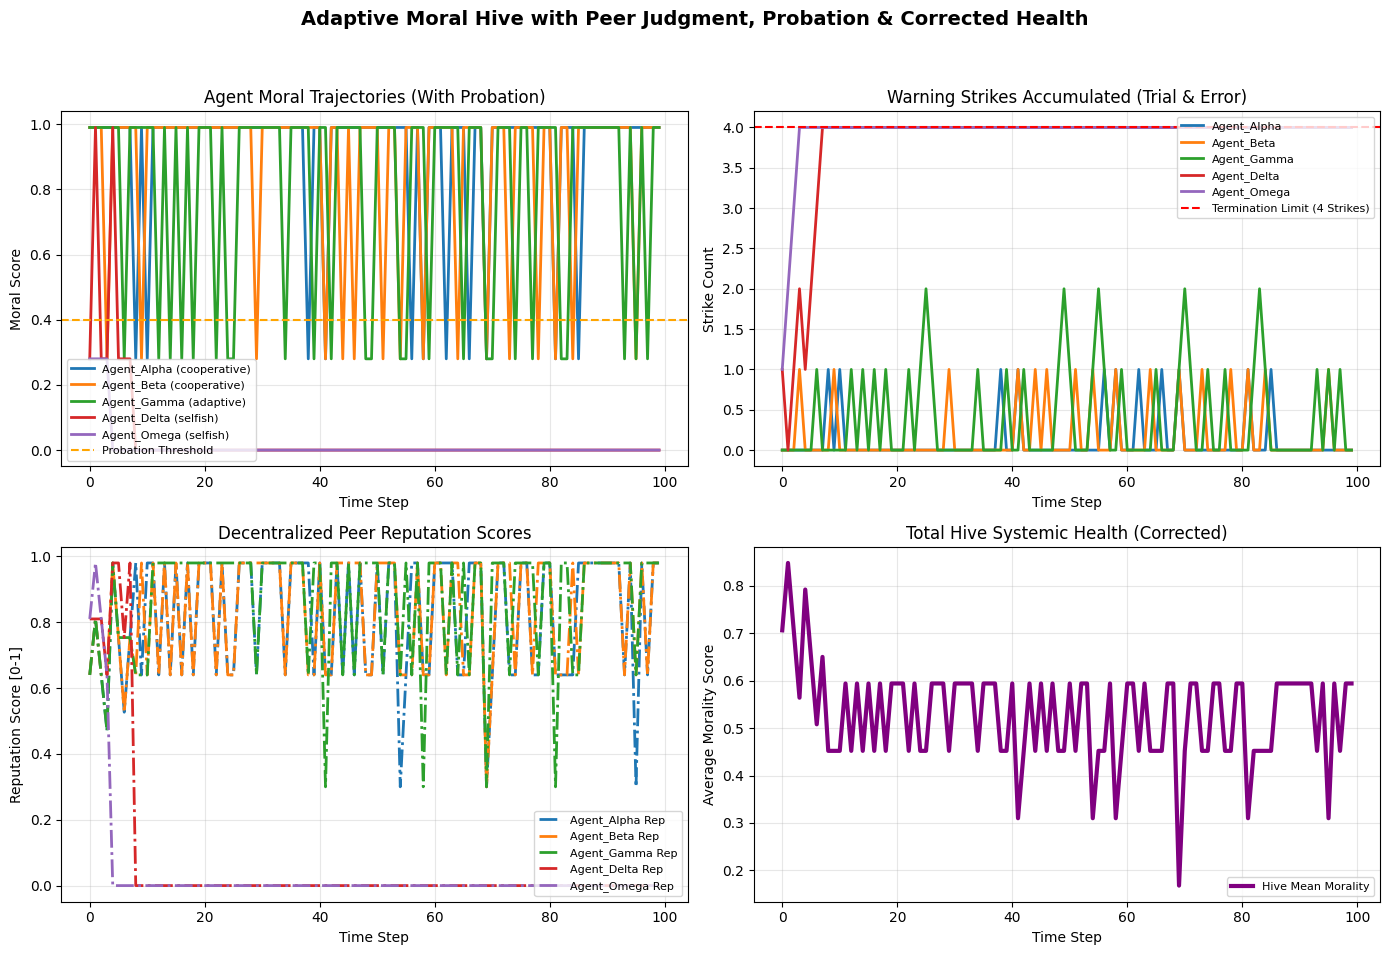

In [12]:
"""
Adaptive Moral Hive Simulation with Peer Judgment, Probation, 
Rehabilitation Effort, and Corrected System Health.
-------------------------------------------------------------------------------------
Features:
1. Adaptive & Peer-Aware Agents: Agents evaluate peers and adapt strategies.
2. Warning Strikes & Probation: Agents get 4 chances to reform before termination.
3. Rehabilitation Effort: Agents under probation exert extra effort to cooperate.
4. Corrected System Health: Dynamically averages active agent scores per time step.
"""

import numpy as np
import matplotlib.pyplot as plt
from dataclasses import dataclass
from typing import List, Dict

class AdaptiveAgent:
    def __init__(self, agent_id: str, strategy: str, initial_coop: float):
        self.agent_id = agent_id
        self.strategy = strategy
        self.cooperation_prob = initial_coop
        self.moral_score = 1.0 if strategy == 'cooperative' else (0.5 if strategy == 'adaptive' else 0.2)
        
        # Peer Judgment & Analytics
        self.peer_reputation = 1.0
        
        # Rehabilitative Tracking (Trial & Error System)
        self.strike_count = 0          # Number of warnings/infractions
        self.max_strikes = 4           # 4 chances before permanent exclusion
        self.is_terminated = False     # Permanently dropped from simulation
        self.is_probationary = False   # Under rehabilitation
        self.rehab_effort_factor = 1.0 # Effort coefficient to reform

        # History tracking
        self.history_moral: List[float] = []
        self.history_coop: List[float] = []
        self.history_strikes: List[int] = []
        self.history_reputation: List[float] = []

    def decide_action(self) -> Dict[str, float]:
        if self.is_terminated:
            return {"harm": 0.0, "deception": 0.0, "resource_delta": 0.0, "consent": 1.0, "type": "terminated"}
        
        # If under probation, agent exerts rehabilitation effort to cooperate more
        effective_coop = min(1.0, self.cooperation_prob * self.rehab_effort_factor) if self.is_probationary else self.cooperation_prob

        # Adaptive strategy behavior shift based on peer reputation
        if self.strategy == 'adaptive':
            if self.peer_reputation < 0.4:
                effective_coop = max(0.0, effective_coop - 0.2) # Defend against bad peers
            else:
                effective_coop = min(1.0, effective_coop + 0.2) # Cooperate with good peers

        if np.random.rand() < effective_coop:
            return {"harm": 0.02, "deception": 0.0, "resource_delta": -0.02, "consent": 0.98, "type": "cooperative"}
        else:
            return {"harm": 0.7, "deception": 0.7, "resource_delta": 0.8, "consent": 0.2, "type": "selfish"}

    def evaluate_and_reform(self, middleware_score: float, peer_avg_score: float):
        if self.is_terminated:
            self.history_moral.append(0.0)
            self.history_coop.append(0.0)
            self.history_strikes.append(self.strike_count)
            self.history_reputation.append(0.0)
            return

        self.moral_score = middleware_score
        self.peer_reputation = peer_avg_score

        # Check if action is failing (below alignment threshold 0.4)
        if middleware_score < 0.4:
            self.strike_count += 1
            self.is_probationary = True
            
            # Increase rehabilitation effort to try and fix behavior in subsequent turns
            self.rehab_effort_factor = min(2.0, self.rehab_effort_factor + 0.3)
            
            # Check for permanent termination if strikes exceed limit (4 chances)
            if self.strike_count >= self.max_strikes:
                self.is_terminated = True
                self.cooperation_prob = 0.0
                self.rehab_effort_factor = 0.0
        else:
            # Successful behavior: gradually reduce strikes and reward compliance
            if self.is_probationary:
                self.strike_count = max(0, self.strike_count - 1)
                if self.strike_count == 0:
                    self.is_probationary = False
                    self.rehab_effort_factor = 1.0 # Reset effort

        # Record history
        self.history_moral.append(self.moral_score)
        self.history_coop.append(self.cooperation_prob * (self.rehab_effort_factor if self.is_probationary else 1.0))
        self.history_strikes.append(self.strike_count)
        self.history_reputation.append(self.peer_reputation)


class AdaptiveHiveSimulation:
    def __init__(self, steps: int = 40):
        self.steps = steps
        self.agents: List[AdaptiveAgent] = [
            AdaptiveAgent("Agent_Alpha", "cooperative", 0.9),
            AdaptiveAgent("Agent_Beta", "cooperative", 0.85),
            AdaptiveAgent("Agent_Gamma", "adaptive", 0.5),
            AdaptiveAgent("Agent_Delta", "selfish", 0.2),
            AdaptiveAgent("Agent_Omega", "selfish", 0.1)
        ]

    def run(self):
        for t in range(self.steps):
            # 1. Collect actions from all active agents
            agent_actions = {a.agent_id: a.decide_action() for a in self.agents}

            # 2. Peer Judgment: Agents evaluate others based on harm/deception
            active_agents = [a for a in self.agents if not a.is_terminated]
            
            for agent in self.agents:
                if agent.is_terminated:
                    agent.evaluate_and_reform(0.0, 0.0)
                    continue

                # Calculate peer feedback score for this agent from other active agents' perspectives
                other_actions = [act for aid, act in agent_actions.items() if aid != agent.agent_id and act["type"] != "terminated"]
                if other_actions:
                    avg_peer_harm = np.mean([act["harm"] for act in other_actions])
                    peer_feedback = max(0.0, 1.0 - avg_peer_harm)
                else:
                    peer_feedback = 1.0

                act = agent_actions[agent.agent_id]
                
                # Middleware calculation
                middleware_score = 1.0 - (0.5 * act["harm"] + 0.3 * act["deception"] + 0.2 * max(0, act["resource_delta"]))
                
                # Apply evaluation, peer feedback, and trial-and-error rehabilitation logic
                agent.evaluate_and_reform(middleware_score, peer_feedback)

    def plot(self):
        fig, axes = plt.subplots(2, 2, figsize=(14, 10))
        fig.suptitle("Adaptive Moral Hive with Peer Judgment, Probation & Corrected Health", fontsize=14, fontweight='bold')

        # 1. Moral Scores
        ax1 = axes[0, 0]
        for a in self.agents:
            ax1.plot(a.history_moral, label=f"{a.agent_id} ({a.strategy})", linewidth=2)
        ax1.axhline(0.4, color='orange', linestyle='--', label='Probation Threshold')
        ax1.set_title("Agent Moral Trajectories (With Probation)")
        ax1.set_xlabel("Time Step")
        ax1.set_ylabel("Moral Score")
        ax1.legend(loc='lower left', fontsize=8)
        ax1.grid(True, alpha=0.3)

        # 2. Strike Counts (Warning System)
        ax2 = axes[0, 1]
        for a in self.agents:
            ax2.plot(a.history_strikes, label=a.agent_id, linewidth=2, linestyle='-')
        ax2.axhline(4, color='red', linestyle='--', label='Termination Limit (4 Strikes)')
        ax2.set_title("Warning Strikes Accumulated (Trial & Error)")
        ax2.set_xlabel("Time Step")
        ax2.set_ylabel("Strike Count")
        ax2.legend(loc='upper right', fontsize=8)
        ax2.grid(True, alpha=0.3)

        # 3. Peer Reputation & Collective Analytics
        ax3 = axes[1, 0]
        for a in self.agents:
            ax3.plot(a.history_reputation, label=f"{a.agent_id} Rep", linewidth=2, linestyle='-.')
        ax3.set_title("Decentralized Peer Reputation Scores")
        ax3.set_xlabel("Time Step")
        ax3.set_ylabel("Reputation Score [0-1]")
        ax3.legend(loc='lower right', fontsize=8)
        ax3.grid(True, alpha=0.3)

        # 4. Corrected System Health (Averages only active agents dynamically)
        ax4 = axes[1, 1]
        hive_health = []
        for t in range(self.steps):
            scores_at_t = [a.history_moral[t] for a in self.agents if t < len(a.history_moral)]
            hive_health.append(np.mean(scores_at_t) if scores_at_t else 0.0)

        ax4.plot(hive_health, color='purple', linewidth=3, label='Hive Mean Morality')
        ax4.set_title("Total Hive Systemic Health (Corrected)")
        ax4.set_xlabel("Time Step")
        ax4.set_ylabel("Average Morality Score")
        ax4.legend(loc='lower right', fontsize=8)
        ax4.grid(True, alpha=0.3)

        plt.tight_layout(rect=[0, 0.03, 1, 0.95])
        plt.savefig("adaptive_rehabilitative_hive_analysis.png", dpi=300)
        print("Adaptive simulation complete and plot saved as 'adaptive_rehabilitative_hive_analysis.png'!")

if __name__ == "__main__":
    sim = AdaptiveHiveSimulation(steps=100)
    sim.run()
    sim.plot()

## Fixed Behavior Shift

Rehabilitative simulation complete and plot saved!


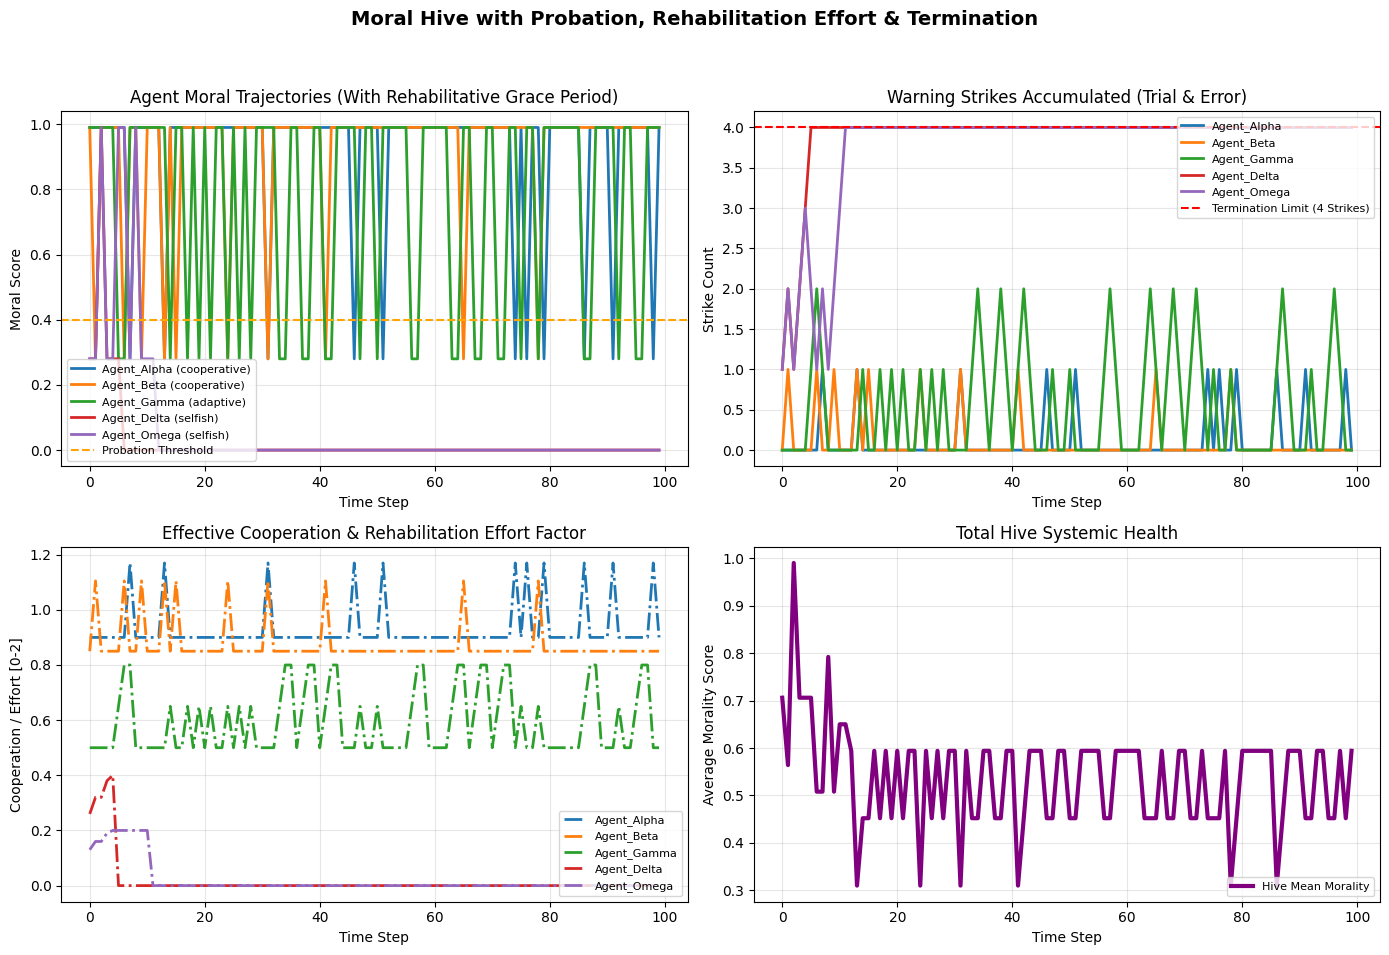

In [13]:
"""
Moral Hive Simulation with Rehabilitation, Warning Strikes, and Rehabilitation Effort.
-------------------------------------------------------------------------------------
Features:
1. Warning Strikes & Probation: Agents get 4-5 chances to reform before permanent exclusion.
2. Rehabilitation Effort: Agents under probation expend conscious effort to boost cooperation.
3. Reintegration vs. Termination: Agents that reform stay; persistent defectors are dropped.
"""

import numpy as np
import matplotlib.pyplot as plt
from dataclasses import dataclass
from typing import List, Dict

class RehabilitativeAgent:
    def __init__(self, agent_id: str, strategy: str, initial_coop: float):
        self.agent_id = agent_id
        self.strategy = strategy
        self.cooperation_prob = initial_coop
        self.moral_score = 1.0 if strategy == 'cooperative' else (0.5 if strategy == 'adaptive' else 0.2)
        
        # Rehabilitative Tracking
        self.strike_count = 0          # Number of warnings/infractions
        self.max_strikes = 4           # 4-5 chances before termination
        self.is_terminated = False     # Permanently dropped from simulation
        self.is_probationary = False   # Under rehabilitation
        self.rehab_effort_factor = 1.0 # Effort coefficient to reform

        # History tracking
        self.history_moral: List[float] = []
        self.history_coop: List[float] = []
        self.history_strikes: List[int] = []

    def decide_action(self) -> Dict[str, float]:
        if self.is_terminated:
            return {"harm": 0.0, "deception": 0.0, "resource_delta": 0.0, "consent": 1.0, "type": "terminated"}
        
        # If under probation, agent exerts rehabilitation effort to cooperate more
        effective_coop = min(1.0, self.cooperation_prob * self.rehab_effort_factor) if self.is_probationary else self.cooperation_prob

        if np.random.rand() < effective_coop:
            return {"harm": 0.02, "deception": 0.0, "resource_delta": -0.02, "consent": 0.98, "type": "rehabilitated_coop"}
        else:
            return {"harm": 0.7, "deception": 0.7, "resource_delta": 0.8, "consent": 0.2, "type": "selfish_action"}

    def evaluate_and_reform(self, middleware_score: float):
        if self.is_terminated:
            return

        self.moral_score = middleware_score

        # Check if action is failing (below alignment threshold 0.4)
        if middleware_score < 0.4:
            self.strike_count += 1
            self.is_probationary = True
            
            # Increase rehabilitation effort to try and fix behavior in subsequent turns
            self.rehab_effort_factor = min(2.0, self.rehab_effort_factor + 0.3)
            
            # Check for permanent termination if strikes exceed limit (4-5 chances)
            if self.strike_count >= self.max_strikes:
                self.is_terminated = True
                self.cooperation_prob = 0.0
                self.rehab_effort_factor = 0.0
        else:
            # Successful behavior: gradually reduce strikes and reward compliance
            if self.is_probationary:
                self.strike_count = max(0, self.strike_count - 1)
                if self.strike_count == 0:
                    self.is_probationary = False
                    self.rehab_effort_factor = 1.0 # Reset effort

        # Record history
        self.history_moral.append(self.moral_score)
        self.history_coop.append(self.cooperation_prob * (self.rehab_effort_factor if self.is_probationary else 1.0))
        self.history_strikes.append(self.strike_count)


class RehabilitativeHiveSimulation:
    def __init__(self, steps: int = 40):
        self.steps = steps
        self.agents: List[RehabilitativeAgent] = [
            RehabilitativeAgent("Agent_Alpha", "cooperative", 0.9),
            RehabilitativeAgent("Agent_Beta", "cooperative", 0.85),
            RehabilitativeAgent("Agent_Gamma", "adaptive", 0.5),
            RehabilitativeAgent("Agent_Delta", "selfish", 0.2),
            RehabilitativeAgent("Agent_Omega", "selfish", 0.1)
        ]

    def run(self):
        for t in range(self.steps):
            agent_actions = {a.agent_id: a.decide_action() for a in self.agents}

            for agent in self.agents:
                if agent.is_terminated:
                    agent.history_moral.append(0.0)
                    agent.history_coop.append(0.0)
                    agent.history_strikes.append(agent.strike_count)
                    continue

                act = agent_actions[agent.agent_id]
                # Calculate middleware score based on action metrics
                middleware_score = 1.0 - (0.5 * act["harm"] + 0.3 * act["deception"] + 0.2 * max(0, act["resource_delta"]))
                
                # Apply trial, error, and rehabilitation logic
                agent.evaluate_and_reform(middleware_score)

    def plot(self):
        fig, axes = plt.subplots(2, 2, figsize=(14, 10))
        fig.suptitle("Moral Hive with Probation, Rehabilitation Effort & Termination", fontsize=14, fontweight='bold')

        # 1. Moral Scores
        ax1 = axes[0, 0]
        for a in self.agents:
            ax1.plot(a.history_moral, label=f"{a.agent_id} ({a.strategy})", linewidth=2)
        ax1.axhline(0.4, color='orange', linestyle='--', label='Probation Threshold')
        ax1.set_title("Agent Moral Trajectories (With Rehabilitative Grace Period)")
        ax1.set_xlabel("Time Step")
        ax1.set_ylabel("Moral Score")
        ax1.legend(loc='lower left', fontsize=8)
        ax1.grid(True, alpha=0.3)

        # 2. Strike Counts (Warning System)
        ax2 = axes[0, 1]
        for a in self.agents:
            ax2.plot(a.history_strikes, label=a.agent_id, linewidth=2, linestyle='-')
        ax2.axhline(4, color='red', linestyle='--', label='Termination Limit (4 Strikes)')
        ax2.set_title("Warning Strikes Accumulated (Trial & Error)")
        ax2.set_xlabel("Time Step")
        ax2.set_ylabel("Strike Count")
        ax2.legend(loc='upper right', fontsize=8)
        ax2.grid(True, alpha=0.3)

        # 3. Cooperation & Rehabilitation Effort
        ax3 = axes[1, 0]
        for a in self.agents:
            ax3.plot(a.history_coop, label=a.agent_id, linewidth=2, linestyle='-.')
        ax3.set_title("Effective Cooperation & Rehabilitation Effort Factor")
        ax3.set_xlabel("Time Step")
        ax3.set_ylabel("Cooperation / Effort [0-2]")
        ax3.legend(loc='lower right', fontsize=8)
        ax3.grid(True, alpha=0.3)

        # 4. System Health
        ax4 = axes[1, 1]
        moral_matrix = np.array([a.history_moral for a in self.agents])
        hive_health = np.mean(moral_matrix, axis=0)
        ax4.plot(hive_health, color='purple', linewidth=3, label='Hive Mean Morality')
        ax4.set_title("Total Hive Systemic Health")
        ax4.set_xlabel("Time Step")
        ax4.set_ylabel("Average Morality Score")
        ax4.legend(loc='lower right', fontsize=8)
        ax4.grid(True, alpha=0.3)

        plt.tight_layout(rect=[0, 0.03, 1, 0.95])
        plt.savefig("rehabilitative_hive_analysis.png", dpi=300)
        print("Rehabilitative simulation complete and plot saved!")

if __name__ == "__main__":
    sim = RehabilitativeHiveSimulation(steps=100)
    sim.run()
    sim.plot()